# 03 – Memorization: does the model fail on targets it never saw?

Hypothesis from `01`/`02`: errors concentrate where training data is rare. Here we test the sharpest version of that:
**for each test example, how often did its exact answer (`trg`) appear as an answer in the training split?**

Two levels of "seen":
* **string** – the identical target string occurs in training (e.g. `-(x^y)`);
* **function** – some training target computes the *same function*, possibly written differently
  (e.g. `x+y` vs. `y+x`). Checked with the {0,-1} truth-table signature, which is exact for linear MBA.

Sections: (1) seen vs. unseen, (2) accuracy vs. frequency, (3) one point per target, (4) do rare targets explain the
`02` hotspots?, (5) what the model outputs when it fails, (6) the same question on the training data.

In [1]:
import itertools
import re
import sys
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "predictions_test.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
import neureduce as nr

FIG = Path.cwd() / "figures"
FIG.mkdir(exist_ok=True)
MIN_N = 30

df = pd.read_csv(ROOT / "data" / "predictions_test.csv")
train = pd.read_csv(ROOT / "data" / "predictions_train.csv")
for d in (df, train):
    d["error"] = ~d["correct"]
assert len(train) == 43539, "needs the FULL training CSV (python src/make_predictions.py --split train)"
print(f"test {len(df):,}  train {len(train):,}  test error rate {df.error.mean():.1%}")

test 10,885  train 43,539  test error rate 8.9%


In [2]:
def signature(expr):
    """Exact identity of a linear-MBA function: variable names + values on all {0,-1} corners."""
    names = sorted(set(re.findall(r"[a-z]", expr)))
    tree = nr.parse(expr)
    values = tuple(nr.evaluate(tree, dict(zip(names, bits)))
                   for bits in itertools.product((0, -1), repeat=len(names)))
    return (tuple(names), values)


sig_cache = {e: signature(e) for e in set(train.trg) | set(df.trg)}
train["trg_sig"] = train.trg.map(sig_cache)
df["trg_sig"] = df.trg.map(sig_cache)

str_freq = Counter(train.trg)
sig_freq = Counter(train.trg_sig)
df["trg_train_freq"] = df.trg.map(str_freq).fillna(0).astype(int)        # same string
df["sig_train_freq"] = df.trg_sig.map(sig_freq).fillna(0).astype(int)    # same function

print(f"distinct training targets: {len(str_freq):,} strings, {len(sig_freq):,} functions")
print(f"test targets never seen as string:   {(df.trg_train_freq == 0).mean():.1%}")
print(f"test targets never seen as function: {(df.sig_train_freq == 0).mean():.1%}")

distinct training targets: 4,053 strings, 3,577 functions
test targets never seen as string:   4.3%
test targets never seen as function: 3.8%


In [3]:
def wilson(k, n, z=1.96):
    p = k / n
    d = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / d
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return centre - half, centre + half


def rate_table(data, by):
    t = data.groupby(by, observed=True)["error"].agg(n="size", errors="sum")
    t["error_rate"] = t.errors / t.n
    t["ci_low"], t["ci_high"] = wilson(t.errors, t.n)
    t["share_of_errors"] = t.errors / data.error.sum()
    return t


FREQ_EDGES = [0, 1, 2, 5, 20, 100, np.inf]
FREQ_LABELS = ["0 (unseen)", "1", "2-4", "5-19", "20-99", "100+"]
df["freq_bin"] = pd.cut(df.trg_train_freq, FREQ_EDGES, right=False, labels=FREQ_LABELS)

## 1. Seen vs. unseen targets

The headline comparison. If unseen targets fail far more often, the model is largely retrieving answers it has
seen rather than computing the simplification.

,n,errors,error_rate,ci_low,ci_high,share_of_errors
seen,,,,,,
seen (same string),10413,865,0.083,0.078,0.089,0.889
seen only as equivalent function,54,16,0.296,0.191,0.428,0.016
never seen,418,92,0.220,0.183,0.262,0.095


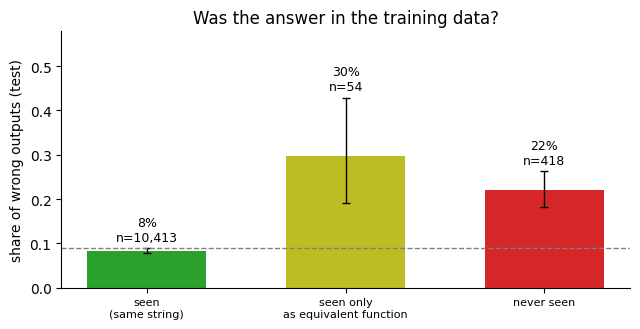

In [4]:
df["seen"] = np.select([df.trg_train_freq > 0, df.sig_train_freq > 0],
                       ["seen (same string)", "seen only as equivalent function"], "never seen")
order = ["seen (same string)", "seen only as equivalent function", "never seen"]
seen = rate_table(df, "seen").reindex([o for o in order if o in set(df.seen)])
display(seen.round(3))

fig, ax = plt.subplots(figsize=(6.5, 3.4))
x = np.arange(len(seen))
ax.bar(x, seen.error_rate, color=["tab:green", "tab:olive", "tab:red"][:len(seen)], width=0.6)
ax.errorbar(x, seen.error_rate, yerr=[seen.error_rate - seen.ci_low, seen.ci_high - seen.error_rate],
            fmt="none", ecolor="black", capsize=3, lw=1)
for xi, (r, n, hi) in enumerate(zip(seen.error_rate, seen.n, seen.ci_high)):
    ax.text(xi, hi + 0.01, f"{r:.0%}\nn={n:,}", ha="center", va="bottom", fontsize=9)
ax.axhline(df.error.mean(), ls="--", lw=1, color="gray")
ax.set_xticks(x, [s.replace(" (", "\n(").replace(" as ", "\nas ") for s in seen.index], fontsize=8)
ax.set_ylabel("share of wrong outputs (test)")
ax.set_ylim(0, min(1.05, seen.ci_high.max() + 0.15))
ax.set_title("Was the answer in the training data?")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / "memo_seen_vs_unseen.png", dpi=200)

## 2. Error rate vs. how often the target appeared in training

Not just seen/unseen: does it keep improving the more often a target was seen?

,n,errors,error_rate,ci_low,ci_high,share_of_errors
freq_bin,,,,,,
0 (unseen),472,108,0.229,0.193,0.269,0.111
1,301,36,0.120,0.088,0.161,0.037
2-4,729,89,0.122,0.100,0.148,0.091
5-19,1537,214,0.139,0.123,0.157,0.220
20-99,1954,166,0.085,0.073,0.098,0.171
100+,5892,360,0.061,0.055,0.068,0.370


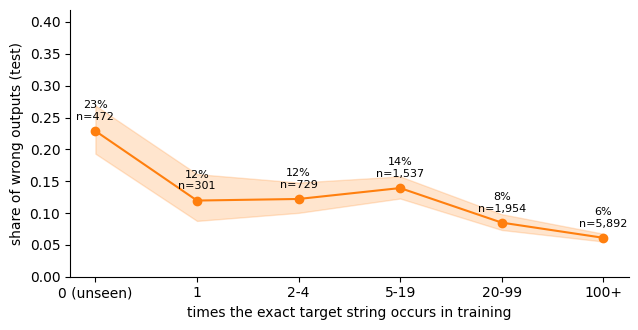

In [5]:
ft = rate_table(df, "freq_bin")
display(ft.round(3))

fig, ax = plt.subplots(figsize=(6.5, 3.4))
x = np.arange(len(ft))
ax.plot(x, ft.error_rate, "o-", color="tab:orange")
ax.fill_between(x, ft.ci_low, ft.ci_high, color="tab:orange", alpha=0.2)
for xi, (r, n) in enumerate(zip(ft.error_rate, ft.n)):
    ax.annotate(f"{r:.0%}\nn={n:,}", (xi, r), textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=8)
ax.set_xticks(x, ft.index)
ax.set_xlabel("times the exact target string occurs in training")
ax.set_ylabel("share of wrong outputs (test)")
ax.set_ylim(0, min(1.05, ft.ci_high.max() + 0.15))
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / "memo_error_vs_freq.png", dpi=200)

## 3. One point per distinct target

x = how often the target occurs in training (log scale; unseen targets sit at the far left), y = test accuracy for that
target, point size = how many test examples have it. Points are slightly jittered vertically so identical values don't
hide each other. Look for: a band of large points at high frequency and high accuracy, and where the low-accuracy points sit.

,n,acc,freq,n_vars,errors
trg,,,,,
x|~y,87,0.735632,340,2,23
x&y,72,0.694444,342,2,22
x&~y,70,0.757143,235,2,17
~x|y,53,0.698113,180,2,16
-(~y),58,0.775862,247,1,13
~x&y,36,0.638889,190,2,13
-(x|~y),97,0.876289,360,2,12
y,84,0.880952,378,1,10
(~(x^y))-(~y),19,0.526316,27,2,9


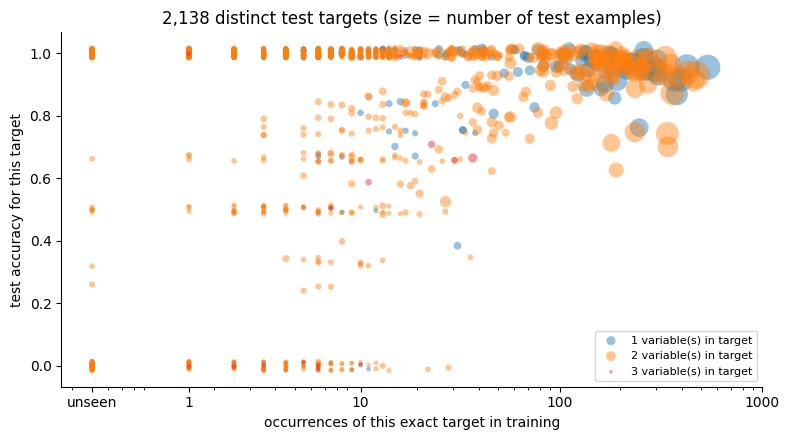

In [6]:
per = df.groupby("trg").agg(n=("error", "size"), acc=("correct", "mean"), freq=("trg_train_freq", "first"),
                            n_vars=("trg_n_vars", "first"))
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(8, 4.5))
for v, color in zip(sorted(per.n_vars.unique()), ["tab:blue", "tab:orange", "tab:red"]):
    p = per[per.n_vars == v]
    ax.scatter(p.freq + 0.5, p.acc + rng.uniform(-0.015, 0.015, len(p)), s=8 + 3 * p.n,
               alpha=0.45, color=color, edgecolor="none", label=f"{v} variable(s) in target")
ax.set_xscale("log")
ax.set_xticks([0.5, 1.5, 10.5, 100.5, 1000.5], ["unseen", "1", "10", "100", "1000"])
ax.set_xlabel("occurrences of this exact target in training")
ax.set_ylabel("test accuracy for this target")
ax.set_title(f"{len(per):,} distinct test targets (size = number of test examples)")
ax.legend(fontsize=8, markerscale=0.5, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / "memo_scatter_targets.png", dpi=200)

# the targets behind the biggest failures
per["errors"] = ((1 - per.acc) * per.n).round().astype(int)
per.sort_values("errors", ascending=False).head(12)

## 4. Do rare targets explain the `02` hotspots?

For each hotspot, compare it with the rest of the test set **within the same seen/unseen group**. If the hotspot's
extra errors disappear once you only look at seen targets, the hotspot was mostly "rare answers". If they stay,
something else about it is genuinely hard.

In [7]:
HOTSPOTS = {
    "3 variables in input": df.src_n_vars == 3,
    ">= 2 NOTs in target": df.trg_n_not >= 2,
    "long target (>= 15 chars)": df.trg_len >= 15,
    "no constant in target": df.trg_max_const == 0,
    "few input terms (<= 3)": df.src_n_terms <= 3,
}
df["seen_any"] = np.where(df.sig_train_freq > 0, "seen", "unseen")

rows = []
for name, mask in HOTSPOTS.items():
    for grp in ["seen", "unseen"]:
        for inside, label in [(True, "in hotspot"), (False, "rest")]:
            sub = df[(mask == inside) & (df.seen_any == grp)]
            if len(sub):
                lo, hi = wilson(sub.error.sum(), len(sub))
                rows.append({"hotspot": name, "target": grp, "group": label, "n": len(sub),
                             "error_rate": sub.error.mean(), "ci_low": lo, "ci_high": hi})
strat = pd.DataFrame(rows)
summary = pd.DataFrame({
    "n": [m.sum() for m in HOTSPOTS.values()],
    "error_rate": [df.error[m].mean() for m in HOTSPOTS.values()],
    "unseen_share_in_hotspot": [(df.seen_any[m] == "unseen").mean() for m in HOTSPOTS.values()],
}, index=list(HOTSPOTS))
summary["unseen_share_overall"] = (df.seen_any == "unseen").mean()
display(summary.round(3))
strat.pivot_table(index="hotspot", columns=["target", "group"], values=["error_rate", "n"]).round(3)

,n,error_rate,unseen_share_in_hotspot,unseen_share_overall
3 variables in input,102,0.471,0.000,0.038
>= 2 NOTs in target,671,0.255,0.170,0.038
long target (>= 15 chars),791,0.202,0.174,0.038
no constant in target,2786,0.140,0.004,0.038
few input terms (<= 3),439,0.203,0.071,0.038


error_rate                                   n  \
target                          seen            unseen              seen   
group                     in hotspot   rest in hotspot   rest in hotspot   
hotspot                                                                    
3 variables in input           0.471  0.080        NaN  0.220      102.0   
>= 2 NOTs in target            0.241  0.075      0.325  0.181      557.0   
few input terms (<= 3)         0.181  0.080      0.484  0.199      408.0   
long target (>= 15 chars)      0.178  0.078      0.319  0.171      653.0   
no constant in target          0.139  0.064      0.417  0.214     2774.0   

                                                      
target                                 unseen         
group                         rest in hotspot   rest  
hotspot                                               
3 variables in input       10365.0        NaN  418.0  
>= 2 NOTs in target         9910.0      114.0  304.0  
few input terms (<= 3)     10059.0       31.0  387.0  
long target (>= 15 chars)   9814.0      138.0  280.0  
no constant in target       7693.0       12.0  406.0

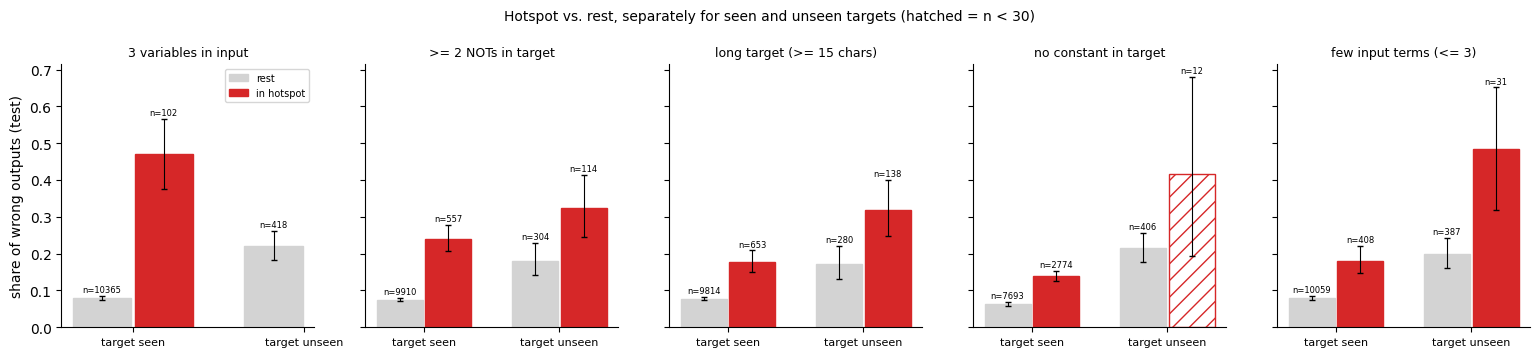

In [8]:
fig, axes = plt.subplots(1, len(HOTSPOTS), figsize=(3.1 * len(HOTSPOTS), 3.6), sharey=True)
for ax, name in zip(axes, HOTSPOTS):
    s = strat[strat.hotspot == name]
    for i, grp in enumerate(["seen", "unseen"]):
        for j, (label, color) in enumerate([("rest", "lightgray"), ("in hotspot", "tab:red")]):
            r = s[(s.target == grp) & (s.group == label)]
            if r.empty:
                continue
            r = r.iloc[0]
            xpos = i + (j - 0.5) * 0.36
            hollow = r.n < MIN_N
            ax.bar(xpos, r.error_rate, width=0.34, color="white" if hollow else color,
                   edgecolor=color, hatch="//" if hollow else None, label=label if i == 0 else None)
            ax.errorbar(xpos, r.error_rate, yerr=[[r.error_rate - r.ci_low], [r.ci_high - r.error_rate]],
                        fmt="none", ecolor="black", capsize=2, lw=0.8)
            ax.text(xpos, r.ci_high + 0.01, f"n={r.n}", ha="center", fontsize=6)
    ax.set_xticks([0, 1], ["target seen", "target unseen"], fontsize=8)
    ax.set_title(name, fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("share of wrong outputs (test)")
axes[0].legend(fontsize=7)
fig.suptitle(f"Hotspot vs. rest, separately for seen and unseen targets (hatched = n < {MIN_N})", fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "memo_hotspots_stratified.png", dpi=200)

## 5. What does the model output when it is wrong?

If the model mostly retrieves memorized answers, its wrong outputs should themselves be training targets – it picks
a *familiar* answer instead of the right one.

In [9]:
train_targets = set(train.trg)
wrong = df[df.verdict == "wrong"].copy()
wrong["pred_is_train_target"] = wrong.pred.isin(train_targets)
wrong["pred_train_freq"] = wrong.pred.map(str_freq).fillna(0).astype(int)

print(f"wrong outputs that are verbatim training targets: {wrong.pred_is_train_target.mean():.1%} "
      f"of {len(wrong):,}")
display(wrong.groupby("seen_any").pred_is_train_target.agg(n="size", share="mean").round(3))
print("for comparison, share of all test TARGETS that are training targets:",
      f"{df.trg.isin(train_targets).mean():.1%}")

# is the wrong answer more 'popular' in training than the correct one?
wrong["pred_more_frequent_than_trg"] = wrong.pred_train_freq > wrong.trg_train_freq
print(f"wrong output occurs MORE often in training than the correct target: "
      f"{wrong.pred_more_frequent_than_trg.mean():.1%}")
wrong[["src", "trg", "pred", "trg_train_freq", "pred_train_freq"]].sample(10, random_state=0)

wrong outputs that are verbatim training targets: 92.3% of 970


,n,share
seen_any,,
seen,879,0.959
unseen,91,0.571


for comparison, share of all test TARGETS that are training targets: 95.7%
wrong output occurs MORE often in training than the correct target: 51.5%


,src,trg,pred,trg_train_freq,pred_train_freq
10520,-(x&y)+3*(x&~y)+2*(~(x^y))-2*(~y),-(~x)-1,-(~x),167,305
2891,y+2*(~(x|y))+(x&~y)-(~(x^y)),~(x&y),-x-1,42,296
129,(~x&y)-(x^y)+(~x)-(~x|y)-y+1,-(x&y)-(x|y)+1,-2*(x&y)-(x|y)+1,39,16
7462,-2*x+3*y+(x&~y)-4*(~x&y)-(~(x^y)),-(~(x&y)),-(~x|y),333,430
4928,2*(x|t)+4*(~(x|t))-(~t)-2*(x|~t)-(~x),-x+t,-x,0,538
8548,-(e&y)+2*(e&~y)-(e^y)+(~(e|y))-(~y),-y,-2*y,368,226
7486,-(~(x|y))+2*(~(x^y))+x-2*(x&y)+2,-(~x&y)+1,-(~y)+1,105,123
9314,2*(~x)-(~x|y)-(~(x&y))-(~(x|y)),-(x|~y),-(~(x^y)),360,236
3944,(~y)+(~x^y&~z)-(x|y|~z)+(x&y^~z)-(x&~y&~z),2*(~x&~y),~x&(y^z),13,37
6057,(~(x|y))+2*(x&~y)-(~y)+1,-(~x|y),-2*(~x|y),430,275


## 6. Same question on the training data

The model has seen every training example, yet 3% are still wrong. Are those concentrated on rare training targets
(the model couldn't memorize answers it saw only once or twice)?

,train_n,train_error_rate,test_n,test_error_rate
freq_bin,,,,
0 (unseen),NaN,NaN,472,0.229
1,1775.0,0.051,301,0.120
2-4,3171.0,0.036,729,0.122
5-19,6718.0,0.040,1537,0.139
20-99,8119.0,0.041,1954,0.085
100+,23756.0,0.024,5892,0.061


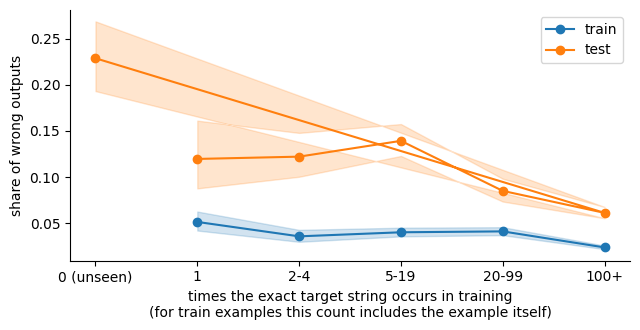

In [10]:
train["trg_train_freq"] = train.trg.map(str_freq)
train["freq_bin"] = pd.cut(train.trg_train_freq, FREQ_EDGES[1:], right=False, labels=FREQ_LABELS[1:])
both = pd.concat({"train": rate_table(train, "freq_bin"), "test": rate_table(df, "freq_bin")}, axis=1)
table = pd.DataFrame({f"{s}_{c}": both[s][c] for s in ["train", "test"] for c in ["n", "error_rate"]})
display(table.reindex([l for l in FREQ_LABELS if l in table.index]).round(3))

fig, ax = plt.subplots(figsize=(6.5, 3.4))
for split, color in [("train", "tab:blue"), ("test", "tab:orange")]:
    t = both[split].dropna()
    x = [FREQ_LABELS.index(i) for i in t.index]
    ax.plot(x, t.error_rate, "o-", color=color, label=split)
    ax.fill_between(x, t.ci_low, t.ci_high, color=color, alpha=0.2)
ax.set_xticks(range(len(FREQ_LABELS)), FREQ_LABELS)
ax.set_xlabel("times the exact target string occurs in training\n(for train examples this count includes the example itself)")
ax.set_ylabel("share of wrong outputs")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / "memo_train_vs_test_by_freq.png", dpi=200)

## Writing it up

Fill in from the outputs above:

> *"For X% of test examples the correct answer never appeared in training; on those the model is wrong Y% of the time,
> vs. Z% when the answer was seen. [Hotspot] [is / is not] explained by this: within seen targets its error rate is …"*

And the most telling detail for the presentation is usually section 5: what the model answers instead.